# Analyse des accidents de la route avec PySpark : RDD, DataFrame et SparkSQL

**Cours** : Fondements et Applications du Big Data — TP 2
**Auteur** : Antoine Chiausa

## Introduction

On reproduit l'article [*Big Data Analysis of Road Crash Data using PySpark*](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588) (Rakesh Nain) : analyse des accidents de la route en Australie-Méridionale (2012–2019) avec les trois API de Spark.

**Le code des sections 3 à 5 est celui de l'article**, recopié sans modification depuis son [dépôt GitHub](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial)

| Partie | Contenu |
|---|---|
| 3. RDD | Lecture, partitionnement, requêtes avec `map` / `filter` / `groupByKey` |
| 4. DataFrame | Requêtes par colonnes, jointure, gravité des accidents selon l'alcool et les drogues |
| 5. Trois API | Deux requêtes écrites en RDD, DataFrame et SparkSQL |

## 1. Environnement

Initialisation de l'environnement Spark

In [2]:
import os, subprocess, sys
from pathlib import Path

os.environ["JAVA_HOME"] = subprocess.run(["/usr/libexec/java_home", "-v", "17"], capture_output=True, text=True).stdout.strip()
os.environ["PYSPARK_PYTHON"] = sys.executable        # les processus Python de Spark utilisent le même interpréteur

DEPOT = Path("Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial")
print("Dossier de travail :", Path.cwd())

Dossier de travail : /Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/TP2-etude_de_cas-article_medium


### Imports de l'article

In [3]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

### Configuration de Spark

Comme dans l'article, Spark tourne en mode **`local[*]`** : calcul **parallèle** sur les cœurs d'une seule machine, et non **distribué** sur plusieurs machines. Sur un cluster, seul le paramètre `master` changerait.

In [4]:
# local[*]: run Spark in local-mode(parallel computing) with as many working processors as logical cores on your machine
# If we want Spark to run locally with 'k' worker threads, we can specify as "local[k]".
master = "local[*]"

# The `appName` field is a name to be shown on the Spark cluster UI page
app_name = "Big data Analysis of Road Crash Data"

# Setup configuration parameters for Spark
spark_conf = SparkConf().setMaster(master).setAppName(app_name)

### Création de la SparkSession

In [5]:
# creating a SparkContext object 
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/16 10:05:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/16 10:05:49 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


## 2. Jeu de données

Données ouvertes du ministère des transports d'Australie-Méridionale (DPTI), fournies dans le dépôt de l'article. Description des colonnes : `metadata-for-road-crash.pdf`.

| Table | Une ligne = | Colonnes utiles |
|---|---|---|
| **Crash** | un accident | `REPORT_ID`, `Suburb`, `Total Cas` (victimes), `Total Fats` (morts), `Crash Type`, `CSEF Severity`, `DUI Involved` (alcool), `Drugs Involved` |
| **Units** | un véhicule (ou piéton) impliqué | `REPORT_ID`, `Veh Reg State`, `Veh Year`, `Sex`, `Age`, `Licence Type` |

Les deux tables se joignent sur **`REPORT_ID`** : un accident a un ou plusieurs véhicules. Un fichier CSV par an et par table.

## 3. Analyse avec les RDD

### 3.1 Création des RDD

- `parallelize()` distribue une collection Python ;
- `textFile()` lit des fichiers texte : chaque ligne devient un élément du RDD.

In [6]:
## FROM A LIST
# By default the number of partitions will be the number of threads
data_list = [i for i in range(10)]
#print(data_list)
rdd = sc.parallelize(data_list)
# You can verify the number of partitions of the data 
print('Default partitions: ',rdd.getNumPartitions())
# the function parallelize can have a second argument to indicate manually how many
# partitions for the data
rdd = sc.parallelize(data_list,5)
# Verify the new number of partitions of the data 
print('Manual partitions: ',rdd.getNumPartitions())
# Show the data by performing the action *collect*
rdd.collect()

Default partitions:  8
Manual partitions:  5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [7]:
# Importing all the "Units" csv files from downloaded 2012–2019 South Australia Road Crash Data into a single RDD.
# creating RDD object by reading csv file
units_rdd = sc.textFile('./Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/units_data/*.csv')

# Importing all the "Crashes" csv files from 2012–2019 into a single RDD.
# creating RDD object by reading csv file
crash_rdd = sc.textFile('./Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/crash_data/*.csv')

### 3.2 Suppression des en-têtes

Chaque fichier commence par la même ligne d'en-tête : un seul `filter` les retire toutes.

In [8]:
# Removing the header of units_rdd
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)   #filter out header
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(10))

Total count of units_rdd:  272591
['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,', '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,', '"2012-2-21/08/2019","02",0,"SA","Motor Cars - Sedan","1993","West",,,,,,"Not Towing","Parked","000",,,', '"2012-3-21/08/2019","01",0,"SA","Motor Cars - Sedan","XXXX","North East","Male","050","SA",,"Full","Trailer","Straight Ahead","006","5107",,', '"2012-3-21/08/2019","02",0,"SA","Motor Cars - Sedan","2006","North East","Male","044","SA",,"Full","Not Towing","Straight Ahead","003","5092",,', '"2012-3-21/08/2019","03",0,,"Other Inanimate Object",,,,,,,,,,,,,', '"2012-4-21/08/2019","01",0,"SA","Station Wagon","2009","South West","Female","0

In [9]:
# Removing the header of crash_rdd
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)   #filter out header
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(10))

Total count of crash_rdd:  127672
['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"', '"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1

### 3.3 Partitionnement

Par défaut, Spark découpe les fichiers en partitions de taille comparable. On peut aussi imposer un **partitionnement par clé** : une partition pour les véhicules immatriculés en Australie-Méridionale (`SA`), une pour tous les autres.

In [10]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


In [11]:
# define a function which will be applied to each rdd element
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[3], [x for i,x in enumerate(array_line) if i!=3] )
units_state_rdd = units_rdd.map(parseRecord)

In [12]:
# define function to partition data into two parts, one only for SA state and other one for alll the states
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1
    
SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

In [13]:
#A Function to print the number of elements in each partion of the given rdd
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().collect()
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().collect()
    
    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if len(partition) > 0:
            print(f"Partition {index}: {len(partition)} records")
print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


### 3.4 Requête : âge moyen des conducteurs par sexe

In [14]:
# define a function that will be applied to each rdd element, apply filter on it and returns only gender and age only
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))
gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd=gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd= filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x),2))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

### 3.5 Requête : véhicules les plus anciens et les plus récents

In [15]:
# define a function that will be applied to each rdd element, apply filter on it and
# returns only Registration State, Year and Unit type only
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]
year_rdd = units_rdd.map(parseYear)
clean_year_rdd=year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]


Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


## 4. Analyse avec les DataFrames

### 4.1 Création des DataFrames

À partir d'une liste Python, puis à partir de fichiers CSV.

In [16]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
#display the rows of the dataframe
df.show(5)
#view the schema
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows
root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



In [17]:
df = spark.read.csv("Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/data for given tutorials/bank.csv",header=True)

In [18]:
units_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/units_data/*.csv')
crash_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load('./Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/crash_data/*.csv')

### 4.2 Accidents à Adélaïde avec plus de 3 victimes

In [19]:
# changing the type of column("Total Cas'") to interger type
crash_df = crash_df.withColumn('Total Cas',F.col('Total Cas').cast(IntegerType()))
# applying filter
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
adelaide_crash_casualty_df.collect()

[Row(REPORT_ID='2012-4842-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Thursday', Time='04:00 pm', Area Speed='050', Position Type='Not Divided', Horizontal Align='Straight road', Vertical Align='Level', Other Feat='Not Applicable', Road Surface='Sealed', Moisture Cond='Dry', Weather Cond='Not Raining', DayNight='Daylight', Crash Type='Rear End', Unit Resp='01', Entity Code='Driver Rider', CSEF Severity='2: MI', Traffic Ctrls='No Control', DUI Involved=None, Drugs Involved=None, ACCLOC_X='1327421.54', ACCLOC_Y='1669848.73', UNIQUE_LOC='13274221669849'),
 Row(REPORT_ID='2012-5769-21/08/2019', Stats Area='1 City', Suburb='ADELAIDE', Postcode='5000', LGA Name='CITY OF ADELAIDE', Total Units='2', Total Cas=4, Total Fats='0', Total SI='0', Total MI='4', Year='2012', Month='March', Day='Friday', Time='09:30 am', Area Speed='050', Pos

### 4.3 Les 10 accidents avec le plus de victimes

In [20]:
crash_df.sort(col('Total Cas'), ascending=False).show(10)

+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--------+----------+-------------+--------------------+--------------+--------------+------------+-------------+------------+--------+-----------+---------+------------+-------------+---------------+------------+--------------+----------+----------+--------------+
|           REPORT_ID|    Stats Area|       Suburb|Postcode|            LGA Name|Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|   Month|      Day|    Time|Area Speed|Position Type|    Horizontal Align|Vertical Align|    Other Feat|Road Surface|Moisture Cond|Weather Cond|DayNight| Crash Type|Unit Resp| Entity Code|CSEF Severity|  Traffic Ctrls|DUI Involved|Drugs Involved|  ACCLOC_X|  ACCLOC_Y|    UNIQUE_LOC|
+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--

### 4.4 Nombre de morts par type d'accident

In [21]:
crash_df.groupBy('Crash Type').agg(F.sum('Total Fats').alias('Total fatalities')).sort(col('Total fatalities'), ascending=False).show()

+--------------------+----------------+
|          Crash Type|Total fatalities|
+--------------------+----------------+
|    Hit Fixed Object|           245.0|
|             Head On|           136.0|
|      Hit Pedestrian|           109.0|
|           Roll Over|            93.0|
|         Right Angle|            82.0|
|            Rear End|            33.0|
|          Side Swipe|            30.0|
|          Right Turn|            26.0|
|  Hit Parked Vehicle|            10.0|
|          Hit Animal|             7.0|
|               Other|             5.0|
|Left Road - Out o...|             3.0|
|  Hit Object on Road|             2.0|
+--------------------+----------------+



### 4.5 Victimes par quartier quand le conducteur n'a pas de permis

In [22]:
# joining both dataframes
complete_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID,how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced').groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows


### 4.6 Gravité des accidents selon l'alcool et les drogues

La gravité est donnée par `CSEF Severity` : `1: PDO` (dégâts matériels seuls), `2: MI` (blessés légers), `3: SI` (blessés graves), `4: Fatal`.

Nombre d'accidents par niveau de gravité :

In [23]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|     4: Fatal|            722|
|        2: MI|          37300|
|       1: PDO|          84775|
|        3: SI|           4875|
+-------------+---------------+



Répartition par gravité dans quatre cas : conducteur positif **a)** aux drogues, **b)** à l'alcool, **c)** aux deux, **d)** à aucun des deux. Le pourcentage est calculé par une **UDF** (fonction Python appliquée ligne par ligne).

In [24]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.show()

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/udf.py:120: RuntimeWarning: Arrow optimization failed to enable because PyArrow or Pandas is not installed. Falling back to a non-Arrow-optimized UDF.
  warnings.warn(


+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            117|        6.31%|
|        2: MI|           1109|       59.82%|
|       1: PDO|            237|       12.78%|
|        3: SI|            391|       21.09%|
+-------------+---------------+-------------+



In [25]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            136|        3.42%|
|        2: MI|           1243|       31.24%|
|       1: PDO|           2144|       53.88%|
|        3: SI|            456|       11.46%|
+-------------+---------------+-------------+



In [26]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|        2: MI|            151|       50.67%|
|       1: PDO|             36|       12.08%|
|        3: SI|             72|       24.16%|
|     4: Fatal|             39|       13.09%|
+-------------+---------------+-------------+



In [27]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_without_alcohol_drugs)*100, 2)))+"%"
    
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            508|        0.42%|
|        2: MI|          35099|       28.74%|
|       1: PDO|          82430|       67.49%|
|        3: SI|           4100|        3.36%|
+-------------+---------------+-------------+



Regroupement des quatre cas dans un seul tableau (nombres, puis pourcentages), pour le graphique.

In [28]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
# all_df.show()
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]

In [29]:
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs',find_severe_percent_udf1('On Drugs'))
total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]

In [30]:
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol',find_severe_percent_udf2('On Alcohol'))
total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]

In [31]:
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both',find_severe_percent_udf3('On Both'))

total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]

In [32]:
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None',find_severe_percent_udf4('On None'))
all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
# all_df_per.show()

Le résultat est ramené dans pandas pour le tracer. Comme le rappelle l'article, `toPandas()` rapatrie tout dans la mémoire du driver : à réserver aux résultats déjà agrégés (ici 4 lignes).

In [33]:
pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some fea

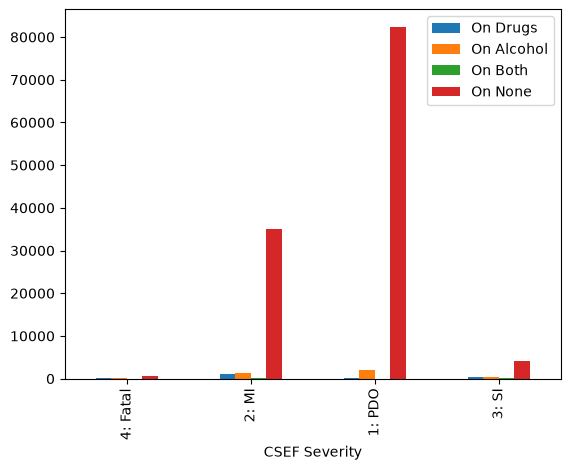

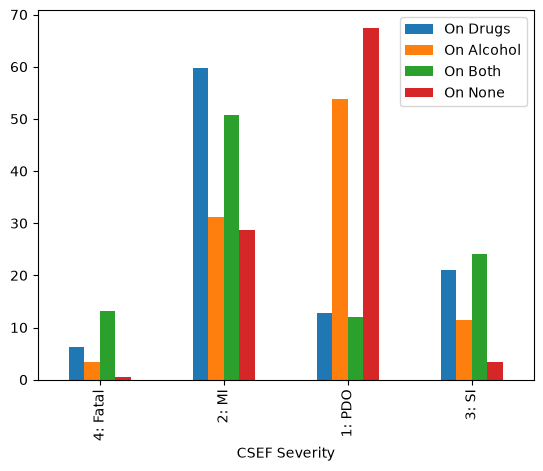

In [34]:
pd_df.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe.png')
pd_df_per.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe_per.png')

## 5. Une même requête, trois API

L'article écrit deux requêtes avec chacune des trois API. SparkSQL s'appuie sur des **vues temporaires** : un DataFrame est enregistré sous un nom de table, puis interrogé en SQL.

### 5.1 Requête A : détails des accidents à Adélaïde

Date et heure de l'accident, nombre de victimes, sexe, âge et type de permis du conducteur, pour le quartier `ADELAIDE`.

In [35]:
# RDD Implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord1(line):
    
    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11])
        return (array_line)
    
pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd=pharsed_rdd.filter(lambda x: x is not None)
filtered_pharsed_rdd.collect()

[['ADELAIDE', '018', 'SA', 'Unknown', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', 'XXX', '', '', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', '027', 'SA', 'Not Towing', '05:00 pm', '0', '2012-May-Friday'],
 ['ADELAIDE', '031', 'SA', 'Not Towing', '05:00 pm', '0', '2012-May-Friday'],
 ['ADELAIDE', '025', 'SA', 'Unknown', '08:00 pm', '0', '2012-June-Friday'],
 ['ADELAIDE', '024', '', '', '08:00 pm', '0', '2012-June-Friday'],
 ['ADELAIDE',
  '055',
  'SA',
  'Not Towing',
  '02:40 pm',
  '0',
  '2012-November-Friday'],
 ['ADELAIDE',
  '049',
  'SA',
  'Not Towing',
  '02:40 pm',
  '0',
  '2012-November-Friday'],
 ['ADELAIDE',
  '083',
  'SA',
  'Not Towing',
  '08:45 am',
  '0',
  '2012-January-Saturday'],
 ['ADELAIDE', '017', '', '', '08:45 am', '0', '2012-January-Saturday'],
 ['ADELAIDE',
  '061',
  'UNKNOWN',
  'Not Towing',
  '12:45 pm',
  '0',
  '2012-January-Monday'],
 ['ADELAIDE',
  '039',
  'UNKNOWN',
  'Not Towing',
  '12:45 pm',
  '0',
  '2012-January-Monday'],


In [36]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
def find_date(d,m,y):
    return y + "-" + m + "-" + d
    
find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date',find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb').collect()

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/udf.py:116: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/udf.py:120: RuntimeWarning: Arrow optimization failed to enable because PyArrow or Pandas is not installed. Falling back to a non-Arrow-optimized UDF.
  warnings.warn(


[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', Age='025', 

In [37]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
joined_table.collect()

[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Male', Age='020', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Female', Age='024', Licence Type='Provisional 1 ', Suburb='ADELAIDE'),
 Row(Date='2012-January-Saturday', Time='08:00 am', Total Cas=0, Sex='Male', Age='025', 

### 5.2 Requête B : victimes par quartier, conducteur sans permis

In [38]:
# RDD implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord2(line):
    return (line[1][1][1], int(line[1][1][5]))
    
filtered_rdd = joined_rdd.filter(lambda x: (x[1][0][9] != "XX") & (x[1][0][8] != "UNKNOWN") & (x[1][0][10] != "Unknown") & (x[1][0][9] is not None) & (x[1][0][10] is not None) & (x[1][0][11] is not None))
pharased_filtered_rdd = filtered_rdd.map(parseRecord2)
result= pharased_filtered_rdd.groupByKey().mapValues(lambda x: sum(x))
result.collect()

[('GOODWOOD', 111),
 ('BOWDEN', 97),
 ('MODBURY NORTH', 374),
 ('MITCHELLVILLE', 4),
 ('WINGFIELD', 634),
 ('MANNINGHAM', 241),
 ('STEPNEY', 2186),
 ('REYNELLA', 189),
 ('MILLBROOK', 118),
 ('RENMARK', 179),
 ('PARK HOLME', 288),
 ('MELROSE PARK', 242),
 ('STIRLING', 247),
 ('VIRGINIA', 365),
 ('NOVAR GARDENS', 89),
 ('PORT PIRIE SOUTH', 53),
 ('SEFTON PARK', 152),
 ('MARRYATVILLE', 732),
 ('THORNLEA', 7),
 ('ANGASTON', 121),
 ('SURREY DOWNS', 84),
 ('CHANDLERS HILL', 140),
 ('RICHMOND', 280),
 ('MYPONGA', 112),
 ('AUBURN', 18),
 ('DUDLEY PARK', 22),
 ('FORRESTON', 49),
 ('GOULD CREEK', 43),
 ('TAILEM BEND', 115),
 ('PORT NOARLUNGA SOUTH', 63),
 ('SEACLIFF', 73),
 ('EDEN HILLS', 120),
 ('ARMAGH', 10),
 ('GLENELG SOUTH', 149),
 ('YAHL', 39),
 ('WILMINGTON', 53),
 ('MARCOLLAT', 11),
 ('CADELL', 8),
 ('SWAN REACH', 18),
 ('STREAKY BAY', 17),
 ('WATTLE RANGE', 10),
 ('FOREST RANGE', 26),
 ('WIRRABARA', 7),
 ('SUTTONTOWN', 41),
 ('DIREK', 44),
 ('CARRICKALINGA', 12),
 ('BLAKISTON', 6),
 ('R

In [39]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
without_lic_df = joined_df.dropna(subset=('Licence Type','Licence Class', 'Lic State'), how='all')
by_suburb_no_lic_no_df = without_lic_df.filter((col('Licence Type') != 'Unknown') &(col('Licence Class') != 'XX') &(col('Lic State') != 'UNKNOWN')).groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.collect()

[Row(Suburb='FLINDERS PARK', Total casualty=620),
 Row(Suburb='TEA TREE GULLY', Total casualty=185),
 Row(Suburb='HACKHAM', Total casualty=179),
 Row(Suburb='SALT CREEK', Total casualty=22),
 Row(Suburb='CUMMINS', Total casualty=31),
 Row(Suburb='WISANGER', Total casualty=11),
 Row(Suburb='MEDINDIE GARDENS', Total casualty=80),
 Row(Suburb='BASKET RANGE', Total casualty=69),
 Row(Suburb='GILLES PLAINS', Total casualty=473),
 Row(Suburb='STANSBURY', Total casualty=30),
 Row(Suburb='MUNDOORA', Total casualty=11),
 Row(Suburb='MURRAY BRIDGE SOUTH', Total casualty=13),
 Row(Suburb='MANNA HILL', Total casualty=3),
 Row(Suburb='HAWKER', Total casualty=22),
 Row(Suburb='MONASH', Total casualty=88),
 Row(Suburb='MAGILL', Total casualty=561),
 Row(Suburb='GLENCOE', Total casualty=17),
 Row(Suburb='WHITE HILL', Total casualty=20),
 Row(Suburb='ORROROO', Total casualty=14),
 Row(Suburb='ECHUNGA', Total casualty=181),
 Row(Suburb='SPENCE', Total casualty=2),
 Row(Suburb='SCEALE BAY', Total casualt

In [40]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT Suburb, COUNT(`Total Cas`)
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
  `Licence Type` != 'Unknown' and
  `Licence Class` != 'XX' and
  `Lic State` != 'UNKNOWN'
GROUP BY Suburb
''')
joined_table.collect()

[Row(Suburb='FLINDERS PARK', count(Total Cas)=620),
 Row(Suburb='TEA TREE GULLY', count(Total Cas)=185),
 Row(Suburb='HACKHAM', count(Total Cas)=179),
 Row(Suburb='SALT CREEK', count(Total Cas)=22),
 Row(Suburb='CUMMINS', count(Total Cas)=31),
 Row(Suburb='WISANGER', count(Total Cas)=11),
 Row(Suburb='MEDINDIE GARDENS', count(Total Cas)=80),
 Row(Suburb='BASKET RANGE', count(Total Cas)=69),
 Row(Suburb='GILLES PLAINS', count(Total Cas)=473),
 Row(Suburb='STANSBURY', count(Total Cas)=30),
 Row(Suburb='MUNDOORA', count(Total Cas)=11),
 Row(Suburb='MURRAY BRIDGE SOUTH', count(Total Cas)=13),
 Row(Suburb='MANNA HILL', count(Total Cas)=3),
 Row(Suburb='HAWKER', count(Total Cas)=22),
 Row(Suburb='MONASH', count(Total Cas)=88),
 Row(Suburb='MAGILL', count(Total Cas)=561),
 Row(Suburb='GLENCOE', count(Total Cas)=17),
 Row(Suburb='WHITE HILL', count(Total Cas)=20),
 Row(Suburb='ORROROO', count(Total Cas)=14),
 Row(Suburb='ECHUNGA', count(Total Cas)=181),
 Row(Suburb='SPENCE', count(Total Cas)=2

### 5.3 Visualisation : gravité des accidents selon l'alcool et les drogues

L'article reprend ici, en une seule cellule, le calcul de la section 4.6 : nombre d'accidents par niveau de gravité et pourcentages, pour les quatre cas **a)** drogues, **b)** alcool, **c)** les deux, **d)** aucun des deux.

In [41]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
all_df.show()
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs',find_severe_percent_udf1('On Drugs'))
total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol',find_severe_percent_udf2('On Alcohol'))
total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))
    
find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both',find_severe_percent_udf3('On Both'))


total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None',find_severe_percent_udf4('On None'))
all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
all_df_per.show()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|     117|       136|     39|    508|
|        2: MI|    1109|      1243|    151|  35099|
|       1: PDO|     237|      2144|     36|  82430|
|        3: SI|     391|       456|     72|   4100|
+-------------+--------+----------+-------+-------+

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
+-------------+--------+----------+-------+-------+



Tracé du graphique des pourcentages.

/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/antoinechiausa/Desktop/Cours/INFO/S9/Big Data/.venv/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


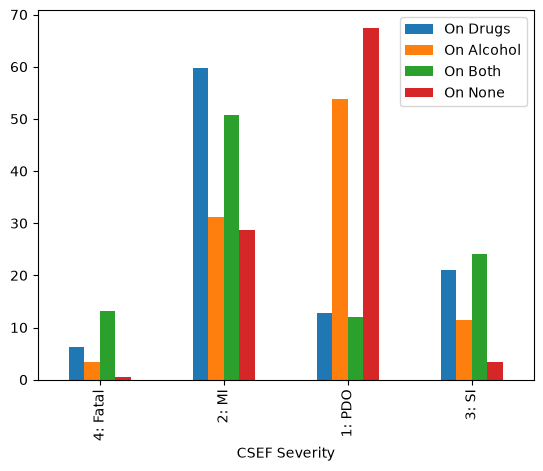

In [42]:
pd_df_per = all_df_per.toPandas()
pd_df_per.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('severe_per.png')

## Annexe — Console Spark après l'exécution

![Console Spark](console_SPARK.png)